In [2]:
#Set up Environment
!pip -q install fastapi uvicorn pandas scikit-learn requests



In [7]:
#Step 2: API setup

from datetime import datetime, timezone
from contextlib import asynccontextmanager
import sqlite3

import pandas as pd
from fastapi import FastAPI, HTTPException, Query
from pydantic import BaseModel, Field
from sklearn.ensemble import IsolationForest


DB_PATH = "/content/smart_city.db"


def init_db():
    with sqlite3.connect(DB_PATH) as conn:
        conn.execute("""
            CREATE TABLE IF NOT EXISTS sensor_readings (
                id INTEGER PRIMARY KEY AUTOINCREMENT,
                device_id TEXT NOT NULL,
                location TEXT NOT NULL,
                sensor_type TEXT NOT NULL,
                value REAL NOT NULL,
                timestamp TEXT NOT NULL
            )
        """)


@asynccontextmanager
async def lifespan(app: FastAPI):
    init_db()
    yield


app = FastAPI(
    title="Smart City IoT Analytics API",
    description="Sensor ingestion, time-series analytics and anomaly detection",
    version="1.0.0",
    lifespan=lifespan
)


class SensorReading(BaseModel):
    device_id: str = Field(min_length=1, max_length=50)
    location: str = Field(min_length=1, max_length=100)
    sensor_type: str = Field(
        pattern="^(traffic|air_quality|energy|parking|waste)$"
    )
    value: float = Field(ge=0, allow_inf_nan=False)
    timestamp: datetime


def read_data():
    with sqlite3.connect(DB_PATH) as conn:
        return pd.read_sql_query(
            "SELECT * FROM sensor_readings ORDER BY timestamp",
            conn
        )


@app.get("/")
def home():
    return {
        "project": "Smart City IoT Analytics API",
        "status": "running",
        "docs": "/docs"
    }


@app.get("/health")
def health():
    return {"status": "healthy"}


@app.post("/sensor-data", status_code=201)
def ingest_sensor_data(reading: SensorReading):
    timestamp = reading.timestamp

    if timestamp.tzinfo is None:
        timestamp = timestamp.replace(tzinfo=timezone.utc)

    with sqlite3.connect(DB_PATH) as conn:
        cursor = conn.execute("""
            INSERT INTO sensor_readings
            (device_id, location, sensor_type, value, timestamp)
            VALUES (?, ?, ?, ?, ?)
        """, (
            reading.device_id,
            reading.location,
            reading.sensor_type,
            reading.value,
            timestamp.isoformat()
        ))

    return {
        "status": "success",
        "reading_id": cursor.lastrowid,
        "device_id": reading.device_id,
        "message": "Sensor reading stored"
    }


@app.get("/sensor-data")
def get_sensor_data(
    sensor_type: str | None = None,
    location: str | None = None,
    limit: int = Query(default=100, ge=1, le=5000)
):
    df = read_data()

    if sensor_type:
        df = df[df["sensor_type"] == sensor_type]

    if location:
        df = df[df["location"] == location]

    return df.tail(limit).to_dict(orient="records")


@app.get("/analytics/summary")
def analytics_summary():
    df = read_data()

    if df.empty:
        return {"message": "No readings available yet"}

    summary = (
        df.groupby("sensor_type")["value"]
        .agg(["count", "mean", "min", "max"])
        .round(2)
        .reset_index()
    )

    return {
        "total_readings": len(df),
        "summary": summary.to_dict(orient="records")
    }


@app.get("/analytics/time-series")
def time_series(
    sensor_type: str,
    location: str | None = None
):
    df = read_data()
    df = df[df["sensor_type"] == sensor_type]

    if location:
        df = df[df["location"] == location]

    if df.empty:
        return {"message": "No matching readings found"}

    df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
    df = df.sort_values("timestamp")

    df["time_bucket"] = df["timestamp"].dt.floor("h")

    result = (
        df.groupby("time_bucket")["value"]
        .agg(["count", "mean", "min", "max"])
        .round(2)
        .reset_index()
    )

    result["time_bucket"] = result["time_bucket"].astype(str)

    return {
        "sensor_type": sensor_type,
        "location": location,
        "time_series": result.to_dict(orient="records")
    }


@app.get("/alerts/anomalies")
def detect_anomalies(sensor_type: str | None = None):
    df = read_data()

    if sensor_type:
        df = df[df["sensor_type"] == sensor_type]

    if len(df) < 10:
        return {
            "message": "At least 10 readings are required",
            "readings_available": len(df)
        }

    # Analyze each sensor type separately because their units differ.
    output = []

    for kind, group in df.groupby("sensor_type"):
        if len(group) < 10:
            continue

        model = IsolationForest(
            contamination=0.05,
            random_state=42
        )

        group = group.copy()
        group["anomaly"] = model.fit_predict(group[["value"]])
        group = group[group["anomaly"] == -1]

        output.extend(
            group.drop(columns=["anomaly"]).to_dict(orient="records")
        )

    return {
        "method": "Isolation Forest",
        "note": "Anomalies are statistical flags, not confirmed incidents.",
        "anomaly_count": len(output),
        "anomalies": output
    }


In [4]:
#Step 3: Start Server
import threading
import time
import uvicorn

def run_server():
    uvicorn.run(app, host="127.0.0.1", port=8000, log_level="warning")

server_thread = threading.Thread(target=run_server, daemon=True)
server_thread.start()

time.sleep(2)

print("Server started. Open the API docs at:")
print("http://127.0.0.1:8000/docs")

Server started. Open the API docs at:
http://127.0.0.1:8000/docs


In [5]:
#Step 4 — Generate simulated IoT readings

import requests
import random
import math
from datetime import timedelta

random.seed(42)

API = "http://127.0.0.1:8000"

now = datetime.now(timezone.utc)
sensor_types = {
    "traffic": (20, 100),
    "air_quality": (25, 150),
    "energy": (10, 90),
    "parking": (10, 95),
    "waste": (10, 90)
}

sent = 0

for i in range(240):
    kind = list(sensor_types)[i % len(sensor_types)]
    low, high = sensor_types[kind]

    hour = (now - timedelta(minutes=5 * (239 - i))).hour
    daily_pattern = 1 + 0.25 * math.sin(2 * math.pi * hour / 24)

    value = random.uniform(low, high) * daily_pattern

    # Add a few artificial spikes for anomaly testing.
    if i in (55, 121, 197):
        value *= 2.5

    reading = {
        "device_id": f"{kind.upper()}_{i % 3 + 1:03}",
        "location": f"Ward_{i % 4 + 1}",
        "sensor_type": kind,
        "value": round(value, 2),
        "timestamp": (
            now - timedelta(minutes=5 * (239 - i))
        ).isoformat()
    }

    response = requests.post(
        f"{API}/sensor-data",
        json=reading,
        timeout=10
    )

    response.raise_for_status()
    sent += 1

print(f"Successfully submitted {sent} simulated readings.")
print(requests.get(f"{API}/analytics/summary").json())


Successfully submitted 240 simulated readings.
{'total_readings': 240, 'summary': [{'sensor_type': 'air_quality', 'count': 48, 'mean': 87.41, 'min': 23.31, 'max': 216.11}, {'sensor_type': 'energy', 'count': 48, 'mean': 49.94, 'min': 9.53, 'max': 110.16}, {'sensor_type': 'parking', 'count': 48, 'mean': 53.55, 'min': 14.59, 'max': 118.67}, {'sensor_type': 'traffic', 'count': 48, 'mean': 61.21, 'min': 18.3, 'max': 128.87}, {'sensor_type': 'waste', 'count': 48, 'mean': 47.17, 'min': 8.66, 'max': 110.27}]}


In [6]:
#Step 5:Test the end points
tests = [
    "/",
    "/health",
    "/sensor-data?limit=5",
    "/analytics/summary",
    "/analytics/time-series?sensor_type=traffic",
    "/alerts/anomalies"
]

for endpoint in tests:
    response = requests.get(f"{API}{endpoint}")
    print(f"\n{endpoint} — HTTP {response.status_code}")
    print(response.text[:500])


/ — HTTP 200
{"project":"Smart City IoT Analytics API","status":"running","docs":"/docs"}

/health — HTTP 200
{"status":"healthy"}

/sensor-data?limit=5 — HTTP 200
[{"id":236,"device_id":"TRAFFIC_002","location":"Ward_4","sensor_type":"traffic","value":34.82,"timestamp":"2026-10-14T09:29:13.734166+00:00"},{"id":237,"device_id":"AIR_QUALITY_003","location":"Ward_1","sensor_type":"air_quality","value":160.38,"timestamp":"2026-10-14T09:34:13.734166+00:00"},{"id":238,"device_id":"ENERGY_001","location":"Ward_2","sensor_type":"energy","value":34.95,"timestamp":"2026-10-14T09:39:13.734166+00:00"},{"id":239,"device_id":"PARKING_002","location":"Ward_3","sensor_ty

/analytics/summary — HTTP 200
{"total_readings":240,"summary":[{"sensor_type":"air_quality","count":48,"mean":87.41,"min":23.31,"max":216.11},{"sensor_type":"energy","count":48,"mean":49.94,"min":9.53,"max":110.16},{"sensor_type":"parking","count":48,"mean":53.55,"min":14.59,"max":118.67},{"sensor_type":"traffic","count":48,"mean":

Total readings: 240
Sensor types: ['traffic' 'air_quality' 'energy' 'parking' 'waste']


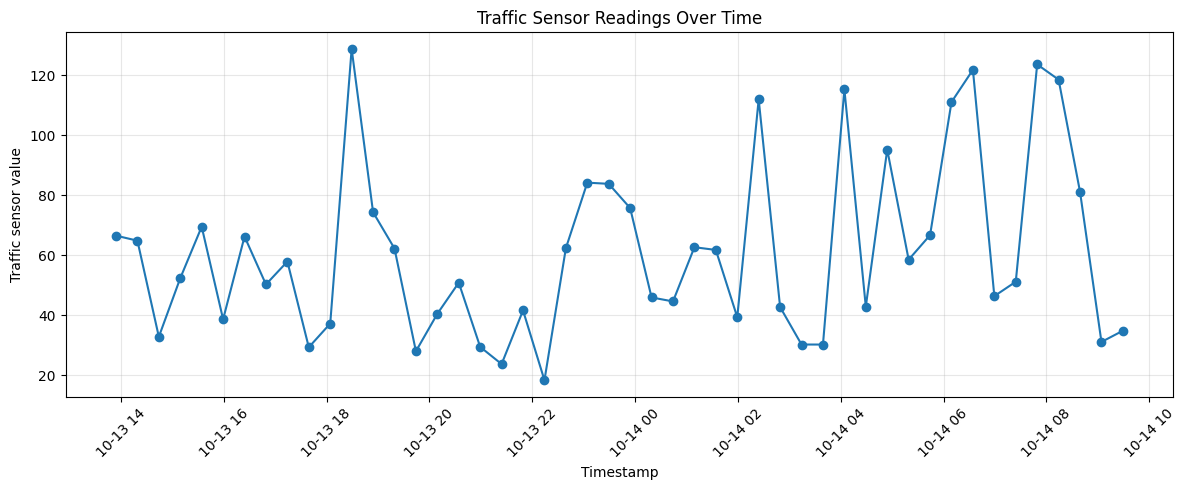

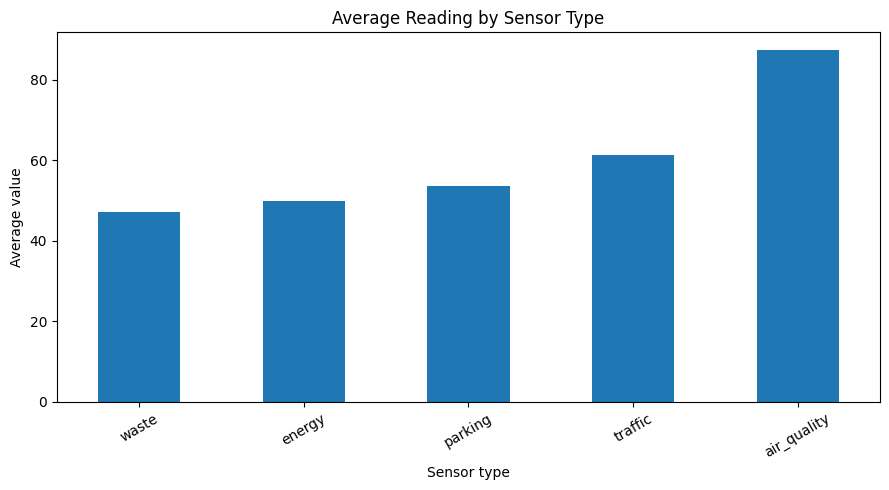

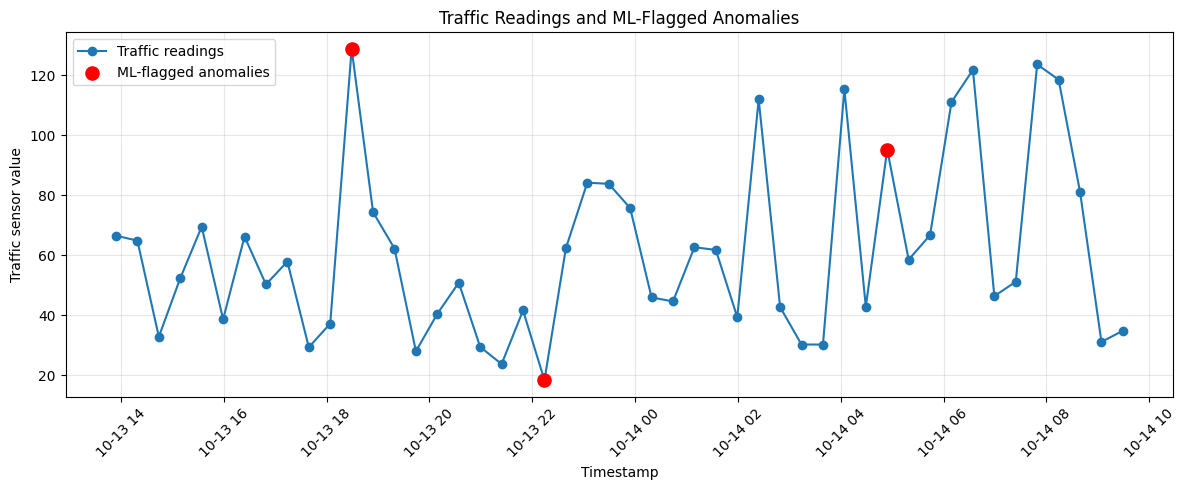

ML method: Isolation Forest
Traffic anomalies flagged: 3
Anomalies are statistical flags, not confirmed incidents.


In [8]:
# Step 6: Visualization
import requests
import pandas as pd
import matplotlib.pyplot as plt

API = "http://127.0.0.1:8000"

# 1. Retrieve the stored sensor readings through our API
response = requests.get(f"{API}/sensor-data?limit=5000")
response.raise_for_status()

df = pd.DataFrame(response.json())
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

print("Total readings:", len(df))
print("Sensor types:", df["sensor_type"].unique())

# 2. Chart: traffic readings over time
traffic = df[df["sensor_type"] == "traffic"].sort_values("timestamp")

plt.figure(figsize=(12, 5))
plt.plot(traffic["timestamp"], traffic["value"], marker="o")
plt.title("Traffic Sensor Readings Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Traffic sensor value")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Chart: average value by sensor type
averages = df.groupby("sensor_type")["value"].mean().sort_values()

plt.figure(figsize=(9, 5))
averages.plot(kind="bar")
plt.title("Average Reading by Sensor Type")
plt.xlabel("Sensor type")
plt.ylabel("Average value")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 4. Chart: ML anomaly detection for traffic readings
response = requests.get(
    f"{API}/alerts/anomalies",
    params={"sensor_type": "traffic"}
)
response.raise_for_status()
anomaly_result = response.json()

anomalies = pd.DataFrame(anomaly_result.get("anomalies", []))

plt.figure(figsize=(12, 5))
plt.plot(
    traffic["timestamp"],
    traffic["value"],
    marker="o",
    label="Traffic readings"
)

if not anomalies.empty:
    anomalies["timestamp"] = pd.to_datetime(
        anomalies["timestamp"], utc=True
    )
    plt.scatter(
        anomalies["timestamp"],
        anomalies["value"],
        color="red",
        s=90,
        label="ML-flagged anomalies",
        zorder=3
    )

plt.title("Traffic Readings and ML-Flagged Anomalies")
plt.xlabel("Timestamp")
plt.ylabel("Traffic sensor value")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("ML method:", anomaly_result.get("method"))
print("Traffic anomalies flagged:", len(anomalies))
print(anomaly_result.get("note", ""))
